In [1]:
# Task 2 (logistic regression)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax as scipy_softmax
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)
SEED = 42

## 1. Load the dataset

In [2]:
#1. Load the dataset
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
df["target"] = 1 - df["target"]          # 1 = malignant (positive), 0 = benign
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
#2. Dataset summary & cleaning

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nClass balance (0 = benign, 1 = malignant):")
print(df["target"].value_counts().rename({0: "benign", 1: "malignant"}))
df.describe().T.head(10)

Shape: (569, 31)
Missing values: 0
Duplicate rows: 0

Class balance (0 = benign, 1 = malignant):
target
benign       357
malignant    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


Rows removed during cleaning: 0


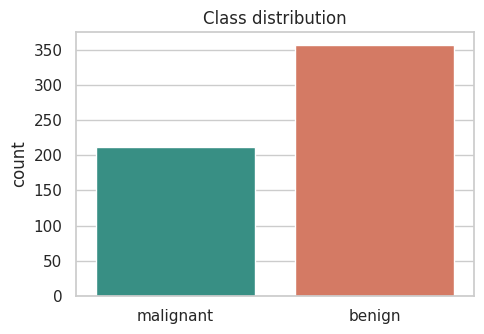

In [4]:
# Cleaning: drop duplicates / missing rows (none expected here, but the pipeline handles them)
n0 = len(df)
df = df.drop_duplicates().dropna().reset_index(drop=True)
print(f"Rows removed during cleaning: {n0 - len(df)}")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x=df["target"].map({0: "benign", 1: "malignant"}), ax=ax, palette=["#2a9d8f", "#e76f51"], hue=df["target"].map({0: "benign", 1: "malignant"}), legend=False)
ax.set_title("Class distribution"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("figures/class_distribution.png", dpi=150); plt.show()

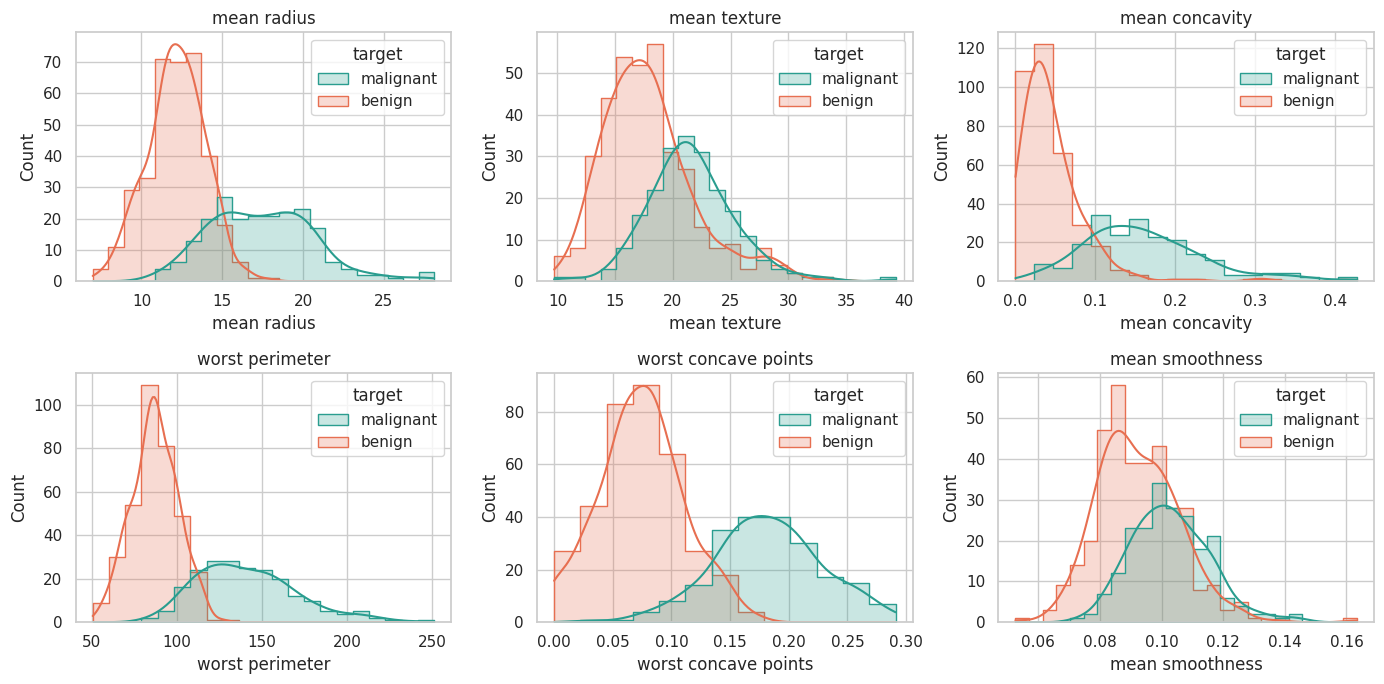

In [5]:
# Feature distributions by class (a representative subset of the 30 features)
feats = ["mean radius", "mean texture", "mean concavity", "worst perimeter", "worst concave points", "mean smoothness"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), feats):
    sns.histplot(data=df, x=f, hue=df["target"].map({0: "benign", 1: "malignant"}), kde=True, ax=ax, palette=["#2a9d8f", "#e76f51"], element="step")
    ax.set_title(f)
plt.tight_layout(); plt.savefig("figures/feature_distributions.png", dpi=150); plt.show()

In [6]:
#3. Feature scaling & train/test split

X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train_s.shape, " Test:", X_test_s.shape)
print("Malignant share  train/test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (455, 30)  Test: (114, 30)
Malignant share  train/test: 0.374 / 0.368


In [7]:
# 4. Train scikit-learn Logistic Regression

model = LogisticRegression(max_iter=1000, random_state=SEED)
model.fit(X_train_s, y_train)
print(f"Train accuracy: {model.score(X_train_s, y_train):.4f}")
print(f"Test accuracy : {model.score(X_test_s, y_test):.4f}")

Train accuracy: 0.9868
Test accuracy : 0.9649


In [8]:
# 5. Custom Sigmoid, Softmax & Cross-Entropy



def sigmoid(z):
    """p = 1 / (1 + e^-z), numerically stable."""
    z = np.asarray(z, dtype=float)
    return np.where(z >= 0, 1 / (1 + np.exp(-z)), np.exp(z) / (1 + np.exp(z)))

def softmax(logits):
    """Row-wise softmax; subtract max for stability. Output rows sum to 1."""
    logits = np.atleast_2d(np.asarray(logits, dtype=float))
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def binary_cross_entropy(y_true, p, eps=1e-15):
    """Loss = -mean[ y*log(p) + (1-y)*log(1-p) ]"""
    p = np.clip(p, eps, 1 - eps)
    y_true = np.asarray(y_true)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def categorical_cross_entropy(y_onehot, P, eps=1e-15):
    P = np.clip(P, eps, 1 - eps)
    return -np.mean(np.sum(y_onehot * np.log(P), axis=1))

In [9]:
# --- Verification against sklearn ---
z = X_test_s @ model.coef_.ravel() + model.intercept_[0]          # z = w^T x + b
p_custom = sigmoid(z)
p_sklearn = model.predict_proba(X_test_s)[:, 1]
print("Sigmoid matches predict_proba :", np.allclose(p_custom, p_sklearn))

bce_custom = binary_cross_entropy(y_test, p_custom)
bce_sklearn = log_loss(y_test, p_sklearn)
print(f"Cross-entropy (custom) : {bce_custom:.6f}")
print(f"Cross-entropy (sklearn): {bce_sklearn:.6f}  -> match: {np.isclose(bce_custom, bce_sklearn)}")

# Softmax: 3-class demo + check vs scipy; binary case equals sigmoid
demo = np.array([[2.0, 1.0, 0.1], [0.5, 2.5, 0.3]])
print("\nSoftmax rows sum to 1:", softmax(demo).sum(axis=1))
print("Matches scipy softmax:", np.allclose(softmax(demo), scipy_softmax(demo, axis=1)))
print("Softmax([z, 0])[0] == sigmoid(z):", np.allclose(softmax(np.c_[z, np.zeros_like(z)])[:, 0], p_custom))

Sigmoid matches predict_proba : True
Cross-entropy (custom) : 0.077265
Cross-entropy (sklearn): 0.077265  -> match: True

Softmax rows sum to 1: [1. 1.]
Matches scipy softmax: True
Softmax([z, 0])[0] == sigmoid(z): True


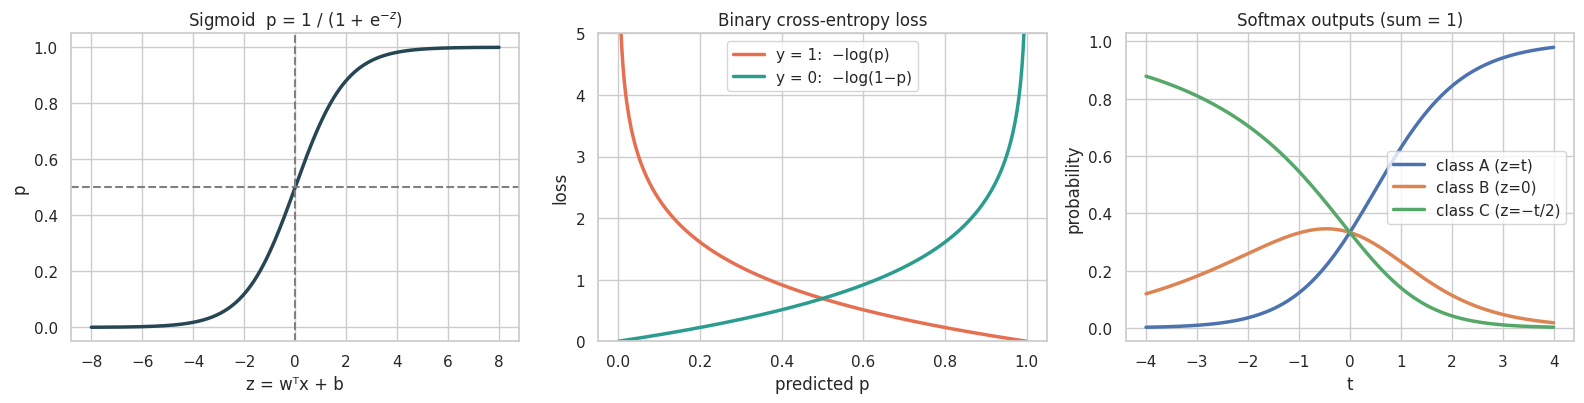

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) Sigmoid
zz = np.linspace(-8, 8, 400)
axes[0].plot(zz, sigmoid(zz), lw=2.5, color="#264653")
axes[0].axhline(0.5, ls="--", c="grey"); axes[0].axvline(0, ls="--", c="grey")
axes[0].set(title="Sigmoid  p = 1 / (1 + e$^{-z}$)", xlabel="z = wᵀx + b", ylabel="p")

# (b) Cross-entropy for y=1 and y=0
pp = np.linspace(0.001, 0.999, 400)
axes[1].plot(pp, -np.log(pp), lw=2.5, label="y = 1:  −log(p)", color="#e76f51")
axes[1].plot(pp, -np.log(1 - pp), lw=2.5, label="y = 0:  −log(1−p)", color="#2a9d8f")
axes[1].set(title="Binary cross-entropy loss", xlabel="predicted p", ylabel="loss", ylim=(0, 5)); axes[1].legend()

# (c) Softmax on a 3-class logit sweep
t = np.linspace(-4, 4, 200)
P = softmax(np.c_[t, np.zeros_like(t), -t / 2])
for i, lab in enumerate(["class A (z=t)", "class B (z=0)", "class C (z=−t/2)"]):
    axes[2].plot(t, P[:, i], lw=2.5, label=lab)
axes[2].set(title="Softmax outputs (sum = 1)", xlabel="t", ylabel="probability"); axes[2].legend()

plt.tight_layout(); plt.savefig("figures/sigmoid_softmax_crossentropy.png", dpi=150); plt.show()

2-feature model test accuracy: 0.9561


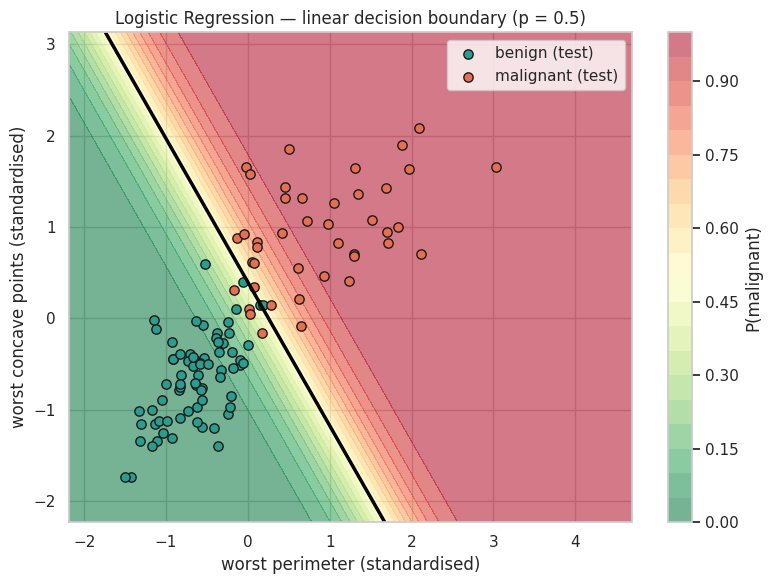

In [11]:
#6. 2D linear decision boundary

f1, f2 = "worst perimeter", "worst concave points"
sc2 = StandardScaler().fit(X_train[[f1, f2]])
A_tr = sc2.transform(X_train[[f1, f2]]); A_te = sc2.transform(X_test[[f1, f2]])
m2 = LogisticRegression(random_state=SEED).fit(A_tr, y_train)
print(f"2-feature model test accuracy: {m2.score(A_te, y_test):.4f}")

xx, yy = np.meshgrid(np.linspace(A_tr[:, 0].min() - .5, A_tr[:, 0].max() + .5, 400),
                     np.linspace(A_tr[:, 1].min() - .5, A_tr[:, 1].max() + .5, 400))
Z = m2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
cs = ax.contourf(xx, yy, Z, levels=20, cmap="RdYlGn_r", alpha=0.55)
plt.colorbar(cs, label="P(malignant)")
ax.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=2.5)
for cls, col, lab in [(0, "#2a9d8f", "benign"), (1, "#e76f51", "malignant")]:
    ax.scatter(A_te[y_test == cls, 0], A_te[y_test == cls, 1], c=col, edgecolor="k", s=45, label=f"{lab} (test)")
ax.set(xlabel=f"{f1} (standardised)", ylabel=f"{f2} (standardised)", title="Logistic Regression — linear decision boundary (p = 0.5)")
ax.legend(); plt.tight_layout(); plt.savefig("figures/decision_boundary_2d.png", dpi=150); plt.show()